# 11 · Numerical dispersion: how wide is the edge of a capture zone, and how does it change with the grid?

Full mixing assumes that the water entering a cell leaves it through all its outflow faces, in proportion to their flows. Near the edge of a capture zone, every cell therefore splits the water it receives into a part that reaches the well and a part that does not. The edge of the zone is smeared over a band of cells with intermediate fractions. This spreading comes from the grid, not from the aquifer. We call it **numerical dispersion**.

This tutorial measures that band on two test problems with references that do not mix:

- **Problem A**, uniform regional flow and a well, against the analytical capture zone of Javandel and Tsang (1986);
- **Problem B**, a recharge-fed model with a river, against flow-weighted MF6 PRT particles on a fine grid.

You will:

1. build problem A on square (DIS) and Voronoi (DISV) cells of 200 to 12.5 m, with the flow along the grid rows and at 30° to them;
2. measure how wide the edge is and how fast it narrows as the cells get smaller;
3. build problem B and its particle reference;
4. repeat the measurements on problem B, west of the river;
5. turn the grid of the tutorial aquifer by 45° to the flow and see how the edge widens;
6. check that the well's shares by source and its mean travel time hardly depend on the mixing;
7. collect the numbers in one table.

**Terms used.** $F$ is the fraction through (tutorial 01): the share of a cell's water that reaches the well. The **band** is the area where $0.1 < F < 0.9$. Its **width** is that area divided by the length of the reference zone edge. It is the mean distance between the $F = 0.1$ and $F = 0.9$ contours across the edge. $h$ is the cell size, and for Voronoi grids the square root of the mean cell area. **Face routing** is an experimental 2D option (`gwsource.experimental.face_routing`, after Chowdhury 2016) that passes water from each inflow face to the outflow faces it reaches, instead of mixing it over the whole cell.

**Runtime:** about 1 minute (the last code cell prints the measured time). The PRT run on the finest grid of problem B takes about 25 s of it. **Prerequisites:** tutorials 01 and 04; `bin/mf6` and `bin/triangle` (downloaded by `scripts/setup_env.sh`); the Python package `vorflow` for section 5 (in `environment.yml`). The study behind this tutorial is written up in [`docs/dispersion_study.md`](../../docs/dispersion_study.md).

## Settings

All settings live in this first cell. Workspaces go to `tutorials/_work/11_numerical_dispersion/` (git-ignored, recreated on every run). The shared helpers are in [`herebedragons.py`](../herebedragons.py). The test problems, the references and the edge metrics of this tutorial are in [`helpers.py`](helpers.py), next to this notebook.

Every per-cell field is sampled on one raster of 2.5 m points shared by all grids, so different grids are compared on the same points. The comparison leaves out a band along the model boundary: 200 m wide in problem A, where the perimeter cells hold fixed heads, and 25 m in problem B.

In [1]:
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent))  # tutorials/ holds the shared helpers
import herebedragons as hbd  # noqa: E402
import helpers  # noqa: E402  (this tutorial's test problems, references and metrics)

import gwsource as gs  # noqa: E402

START = time.perf_counter()  # the notebook prints its run time at the end
WORK = hbd.work_dir("11_numerical_dispersion", clean=True)  # tutorials/_work/... (git-ignored)
MF6 = hbd.mf6_exe()  # <repo>/bin/mf6
TRIANGLE = hbd.exe_path("triangle")  # <repo>/bin/triangle, meshes the Voronoi grids
SIZES_A = (200.0, 100.0, 50.0, 25.0, 12.5)  # m, cell sizes of problem A
SIZES_B = (100.0, 50.0, 25.0, 12.5)  # m, cell sizes of problem B (PRT on the finest is the reference)
ANGLES = (0.0, 30.0)  # degrees between the regional flow and the grid rows (problem A)
KINDS = ("DIS", "DISV")  # square cells and Voronoi cells (Triangle maximum area h^2)
RASTER = 2.5  # m, spacing of the shared comparison raster
MARGIN_A, MARGIN_B = 200.0, 25.0  # m, band along the model boundary left out of the comparison
RIVER_GAP = 50.0  # m, problem B is compared west of x = river - RIVER_GAP
POROSITY = 0.3  # for travel times and PRT
PRT_SUBDIVISIONS = 2  # 16 release points per DIS cell
MAP_H = 50.0  # m, cell size of the maps
FINE = 50.0  # m, "cells of 50 m or less"
STYLES = {  # (grid, method): line style of the convergence plots
    ("DIS", "full mixing"): {"color": "tab:blue", "marker": "o"},
    ("DIS", "face routing"): {"color": "tab:orange", "marker": "s"},
    ("DISV", "full mixing"): {"color": "tab:green", "marker": "^"},
    ("DIS", "cell-averaged exact"): {"color": "0.4", "marker": "x"},
    ("DIS", "PRT"): {"color": "0.4", "marker": "x"},
}
# section 5: the tutorial aquifer of tutorials 01 and 04 on three grids
WELL = "supply_well"  # boundname of its well
ROTATED_SIDE = 100.0 / 3.0 * np.sqrt(2.0)  # m, squares turned 45 degrees (as in tutorial 04)
VORONOI_SIZES = {"background": 25.0, "well_size": 10.0, "river_size": 12.5}  # m, vorflow mesh sizes
TRANSECT_X = 500.0  # m, north-south line on which the width of the edge is measured

plt.rcParams.update({"figure.dpi": 80})
vorflow = hbd.require_vorflow()  # optional dependency: only section 5 needs it
print(f"gwsource {gs.__version__}, vorflow {vorflow.__version__}")

gwsource 0.0.1, vorflow 0.2.0


## 1. Problem A: uniform flow and a well

Problem A is a confined aquifer, 2 km × 2 km, with a transmissivity $T$ of 500 m²/d and a regional hydraulic gradient $i$ of 0.002. The regional discharge per unit width is $U = T i$ = 1 m²/d. One well pumps $Q$ = 500 m³/d. The heads of all perimeter cells are fixed to the analytical head of uniform flow plus a well,

$$h = h_0 - i\,s + \frac{Q}{4\pi T}\ln r^2,$$

where $s$ is the distance along the regional flow and $r$ the distance from the well. The flow inside the domain then approaches uniform flow plus a well. Its capture zone is known exactly (Javandel and Tsang 1986). Far upstream the zone is $Q/U$ = 500 m wide. Its edge, the dividing streamline, passes through a stagnation point $Q/(2\pi U)$ = 80 m downstream of the well.

The cell below builds the problem on five cell sizes, on DIS and Voronoi DISV grids, with the regional flow along the grid rows (0°) and at 30° to them. That makes 20 models. On each it computes three fields:

- **full mixing**, the backward trace of tutorial 01;
- **face routing**, on DIS only;
- the **cell-averaged exact** zone: the analytical zone averaged over each cell. It is the best a field with one value per cell can do, and sets the floor of the band width.

The flux-weighted mean travel time of the water reaching the well is $\sum_i n\,b\,A_i F_i / Q$ under full mixing (tutorial 06), with $n$ the porosity and $b$ the thickness. The analytical value is $n\,b$ times the zone area, over $Q$. So the relative error of the travel time is $\sum_i A_i F_i$ over the analytical zone area, minus 1. The cell computes it for every field.

In [2]:
specs_a = {angle: helpers.ProblemA(angle_deg=angle) for angle in ANGLES}
spec = specs_a[0.0]
print(f"U = {spec.regional_discharge:g} m2/d, zone width Q/U = {spec.rate / spec.regional_discharge:.0f} m, "
      f"stagnation point Q/(2 pi U) = {spec.rate / (2 * np.pi * spec.regional_discharge):.1f} m downstream")

t0 = time.perf_counter()
rasters_a, runs_a, rows = {}, {}, []
for angle, spec in specs_a.items():
    raster = helpers.make_raster(spec.lx, spec.ly, RASTER, MARGIN_A)
    raster.set_reference(helpers.capture_zone_mask(raster.xr, raster.yr, spec))
    rasters_a[angle] = raster
    zone_area = raster.ref.sum() * raster.pixel  # analytical zone area in the whole domain
    for kind in KINDS:
        for h in SIZES_A:
            run = helpers.problem_a_run(WORK / f"a{angle:g}_{kind}_{h:g}", MF6, TRIANGLE, spec, kind, h, raster)
            runs_a[(angle, kind, h)] = run
            for row in helpers.metrics_rows({"angle": angle, "kind": kind, "h": h}, run, raster):
                F = run["fields"][row["method"]]
                row["travel_time_err"] = float(F @ run["step"].area / zone_area - 1.0)
                rows.append(row)
table_a = pd.DataFrame(rows)
cells = table_a.drop_duplicates(["angle", "kind", "h"])
print(f"{len(cells)} models of {cells['cells'].min()} to {cells['cells'].max()} cells, "
      f"traced and compared in {time.perf_counter() - t0:.0f} s")
display(cells[cells["angle"] == 0.0].pivot(index="h", columns="kind", values=["cells", "mean_h"])
        .sort_index(ascending=False).round(0))

U = 1 m2/d, zone width Q/U = 500 m, stagnation point Q/(2 pi U) = 79.6 m downstream


20 models of 91 to 25600 cells, traced and compared in 16 s


cells          mean_h       
kind       DIS     DISV    DIS   DISV
h                                    
200.0    100.0     91.0  200.0  210.0
100.0    400.0    349.0  100.0  107.0
50.0    1600.0   1322.0   50.0   55.0
25.0    6400.0   5207.0   25.0   28.0
12.5   25600.0  20450.0   12.0   14.0

The Voronoi grids made with Triangle at a maximum triangle area of $h^2$ have mean cell sizes of 210, 107, 55, 28 and 14 m. They are a little coarser than the DIS grid of the same $h$. The plots below use the mean cell size.

The maps show the four fields on 50 m cells, with the flow at 30° to the rows. The dashed line is the analytical edge.

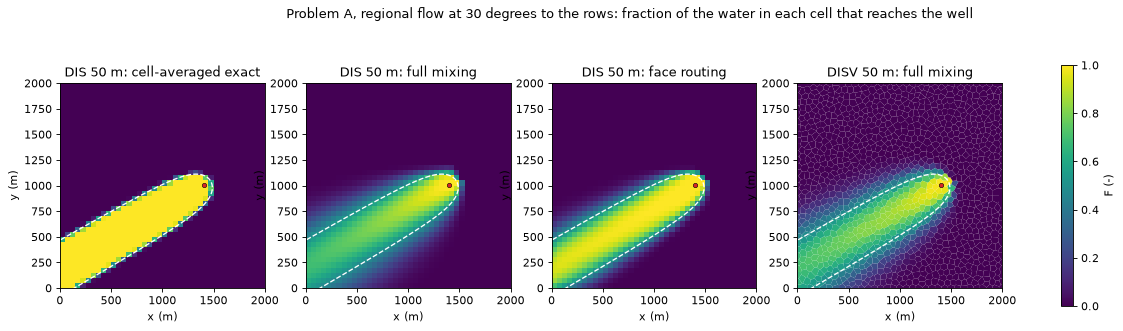

In [3]:
angle = 30.0
spec = specs_a[angle]
x_edge, y_edge = helpers.divide_line(spec)
panels = [("DIS", "cell-averaged exact"), ("DIS", "full mixing"), ("DIS", "face routing"), ("DISV", "full mixing")]
fig, axes = plt.subplots(1, 4, figsize=(19.0, 4.6))
for ax, (kind, method) in zip(axes, panels):
    run = runs_a[(angle, kind, MAP_H)]
    helpers.plot_field(ax, run["model"], run["step"], run["fields"][method], f"{kind} {MAP_H:g} m: {method}",
                       (spec.well_x, spec.well_y))
    ax.plot(x_edge, y_edge, "w--", lw=1.2)
    ax.set_xlim(0.0, spec.lx)
    ax.set_ylim(0.0, spec.ly)
fig.colorbar(axes[-1].collections[0], ax=axes, shrink=0.85, label="F (-)")
fig.suptitle(f"Problem A, regional flow at {angle:g} degrees to the rows: fraction of the water in each cell "
             "that reaches the well")
plt.show()

The cell-averaged exact zone (left) has a band of about one cell: only the cells that the edge crosses hold intermediate values. Full mixing spreads the edge over several cells on each side. The spreading grows with the distance travelled along the edge, so the band is widest far upstream and narrowest near the well. Face routing gives a narrower band. The Voronoi band is about as wide as the DIS band.

## 2. How the edge narrows with the cell size

The table gives the metrics for 50 m and 12.5 m cells. Area errors are relative to the analytical zone. *Missed* is the share of the analytical zone where $F$ is not above the threshold.

In [4]:
COLUMNS = {"area_err_0.01": "area err F>0.01", "area_err_0.1": "area err F>0.1", "area_err_0.5": "area err F>0.5",
           "jaccard_0.5": "Jaccard F>0.5", "missed_0.1": "missed F>0.1", "missed_0.5": "missed F>0.5",
           "band_width": "band width (m)", "band_cells": "band (cells)", "travel_time_err": "travel time err"}


def show(table: pd.DataFrame, index: list[str], columns: dict) -> None:
    # display selected metrics, three decimals (band width in metres, one decimal)
    out = table.set_index(index)[list(columns)].rename(columns=columns)
    display(out.style.format("{:.3f}").format("{:.0f}", subset=["band width (m)"])
            .format("{:.1f}", subset=["band (cells)"]))


selected = table_a[table_a["h"].isin([50.0, 12.5])].sort_values(["angle", "h", "kind"], ascending=[True, False, True])
show(selected, ["angle", "kind", "h", "method"], COLUMNS)

- The **F > 0.5 area** is close to the analytical area: within 5 % at 50 m and within 1 % at 12.5 m, for every method.
- The **F > 0.1 area** never misses more than 0.01 % of the analytical zone, but it is much too large: by 67 to 90 % at 50 m and by 30 to 40 % at 12.5 m under full mixing.
- The band of full mixing is 214 m (0°) and 304 m (30°) wide at 50 m. At 12.5 m it is 105 m and 148 m, that is 8 to 12 cells.

The plots show the whole series. Solid lines: flow along the rows. Dotted: flow at 30°. The dashed guide falls as $h^{0.5}$. The grey band is ±5 %.

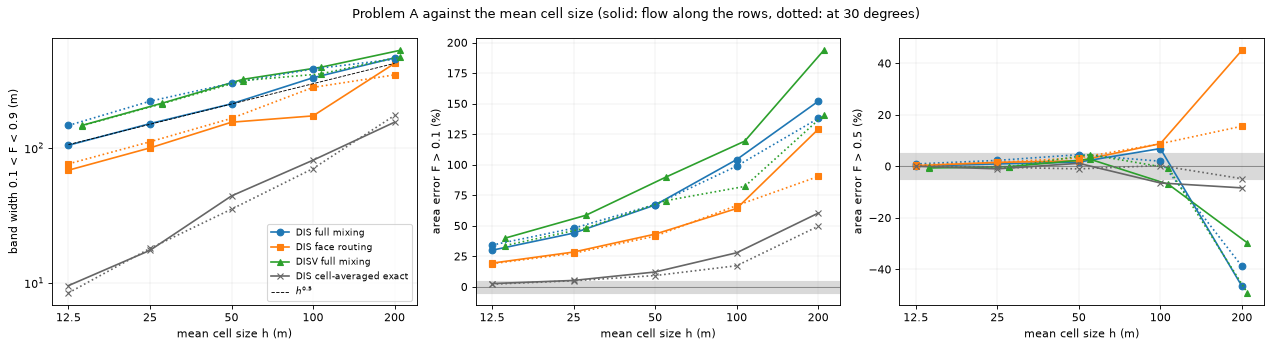

convergence rates: slope of log(metric) against log(mean cell size), five grids


band_width  area_err_0.1
angle kind method                                       
0.0   DIS  cell-averaged exact        1.03          1.15
           face routing               0.60          0.66
           full mixing                0.54          0.59
      DISV cell-averaged exact        1.04          1.08
           full mixing                0.47          0.57
30.0  DIS  cell-averaged exact        1.07          1.09
           face routing               0.57          0.58
           full mixing                0.41          0.51
      DISV cell-averaged exact        1.06          1.03
           full mixing                0.42          0.50

In [5]:
series_a = []
for angle, line in ((0.0, "-"), (30.0, ":")):
    for (kind, method), style in STYLES.items():
        if method != "PRT":
            label = f"{kind} {method}" if angle == 0.0 else None
            series_a.append((label, {"angle": angle, "kind": kind, "method": method}, {**style, "ls": line}))
fig, axes = plt.subplots(1, 3, figsize=(16.0, 4.4))
helpers.plot_convergence(axes, table_a, series_a, guide_h=(12.5, 200.0))
axes[0].legend(fontsize=8)
fig.suptitle("Problem A against the mean cell size (solid: flow along the rows, dotted: at 30 degrees)")
fig.tight_layout()
plt.show()

rates_a = helpers.rates_table(table_a, ["angle", "kind", "method"])
print("convergence rates: slope of log(metric) against log(mean cell size), five grids")
display(rates_a.round(2))

The cell-averaged exact zone converges at first order: its band stays at about 0.7 to 0.9 cells at every size. Full mixing converges at about half order. Its band narrows as about $h^{0.5}$, with fitted rates of 0.41 to 0.54. In cells, the band therefore grows as the grid gets finer, from 2 cells at 200 m to 12 cells at 12.5 m. The spreading behaves like a diffusion with a coefficient proportional to the cell size: the band grows with the square root of $h$ times the distance travelled along the edge.

Face routing narrows the band but keeps the half-order rate (0.57 and 0.60). It still mixes the water across each cell face. The Voronoi grids spread the edge no less than the squares. With the flow at 30°, their band equals that of DIS (147 m against 148 m at about 13 m). With the flow along the rows, it is wider (147 m against 105 m).

## 3. Problem B: a recharge-fed zone and its particle reference

Problem B has the physics of one of the package's test models, without its inactive cells. It is one unconfined layer, 1.5 km × 1 km, with recharge of 1 mm/d, a river along $x$ = 1128 m, a constant head on the west edge and a well pumping 800 m³/d. The well and the river sit at points that are inside cells for every cell size. The river conductance is given per metre of river, so it does not change with the grid.

Here the reference is MF6 PRT, through `gwsource.prt.track_particles` (tutorial 06). On every DIS grid, 16 particles per cell are released in every cell with $F > 0$ and weighted by the cell's recharge. The run on the finest grid, 12.5 m, is the reference. It is compared with the fraction of each cell's recharge that reaches the well. Under full mixing that fraction is $F$ of the cell. Under face routing it is the fraction of the recharge, which enters through the top face.

East of the river all water passes the gaining river, which is a weak sink. The PRT helper, too, treats weak sinks by full mixing: it reduces the weight of a particle by the share that the river removes from each cell it passes. The areas are therefore compared west of the river only, 50 m or more from it, where no method mixes at a weak sink.

In [6]:
spec_b = helpers.ProblemB()
raster_b = helpers.make_raster(spec_b.lx, spec_b.ly, RASTER, MARGIN_B)
raster_b.window &= raster_b.xr < spec_b.riv_x - RIVER_GAP  # west of the river: no weak sinks on the way
runs_b = {}
for kind in KINDS:
    for h in SIZES_B:
        t0 = time.perf_counter()
        run = helpers.problem_b_run(WORK / f"b_{kind}_{h:g}", MF6, TRIANGLE, spec_b, kind, h, POROSITY,
                                    PRT_SUBDIVISIONS)
        run["index"] = helpers.raster_cells(run["model"].modelgrid, raster_b)
        run["seconds"] = time.perf_counter() - t0
        runs_b[(kind, h)] = run
reference = runs_b[("DIS", min(SIZES_B))]
raster_b.set_reference(reference["fields"]["PRT"][reference["index"]])
prt = reference["prt"]
print(f"reference: PRT on DIS {min(SIZES_B):g} m, {reference['model'].n_cells} cells, {prt['n_particles']:,} particles; "
      f"captured flow {prt['captured_flow']:.2f} m3/d of {reference['well_inflow']:.2f} m3/d pumped")
display(pd.DataFrame({key: {"cells": run["model"].n_cells, "mean h (m)": run["model"].mean_cell_size,
                            "seconds": run["seconds"]} for key, run in runs_b.items()}).T.round(1))

rows = []
for (kind, h), run in runs_b.items():
    for row in helpers.metrics_rows({"kind": kind, "h": h}, run, raster_b):
        row["mean_time"] = run["mean_time"][row["method"]]
        row["share_RIV"] = run["shares"][row["method"]]["RIV"]
        rows.append(row)
table_b = pd.DataFrame(rows)

reference: PRT on DIS 12.5 m, 9600 cells, 93,856 particles; captured flow 800.86 m3/d of 800.00 m3/d pumped


cells  mean h (m)  seconds
DIS  100.0   150.0       100.0      0.2
     50.0    600.0        50.0      0.4
     25.0   2400.0        25.0      2.3
     12.5   9600.0        12.5     16.0
DISV 100.0   140.0       103.5      0.1
     50.0    525.0        53.5      0.1
     25.0   1972.0        27.6      0.3
     12.5   7721.0        13.9      1.3

The 93,856 particles capture 800.9 m³/d, 0.1 % more than the pumping. The difference comes from placing a finite number of release points. The run on 12.5 m cells takes most of the time of this cell.

The maps show the PRT reference on 12.5 m cells and the three methods on 50 m cells. The dashed line is the reference edge, the PRT $F = 0.5$ contour. The grey line is the river. The comparison window ends at the dotted line.

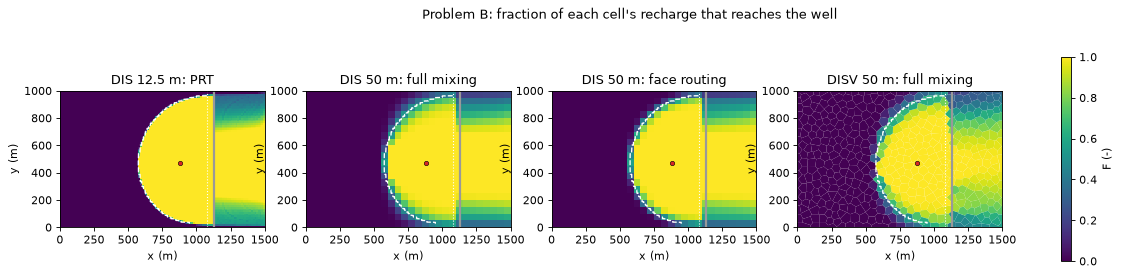

In [7]:
panels = [(("DIS", 12.5), "PRT"), (("DIS", MAP_H), "full mixing"), (("DIS", MAP_H), "face routing"),
          (("DISV", MAP_H), "full mixing")]
xr, yr, ref = raster_b.xr, raster_b.yr, np.ma.masked_where(~raster_b.window, raster_b.ref)
fig, axes = plt.subplots(1, 4, figsize=(19.0, 3.9))
for ax, (key, method) in zip(axes, panels):
    run = runs_b[key]
    helpers.plot_field(ax, run["model"], run["step"], run["fields"][method], f"{key[0]} {key[1]:g} m: {method}",
                       (spec_b.well_x, spec_b.well_y))
    ax.contour(xr, yr, ref, levels=[0.5], colors="w", linestyles="--", linewidths=1.2)
    ax.axvline(spec_b.riv_x, color="0.6", lw=2.0)
    ax.axvline(spec_b.riv_x - RIVER_GAP, color="w", ls=":", lw=1.0)
fig.colorbar(axes[-1].collections[0], ax=axes, shrink=0.85, label="F (-)")
fig.suptitle("Problem B: fraction of each cell's recharge that reaches the well")
plt.show()

The well captures the recharge of an area that reaches back to the west edge. On 50 m cells, full mixing smears its edge over about two cells, face routing over about one. East of the river every method gives partial fractions, because the gaining river takes part of the water of every cell it drains.

## 4. Problem B against the cell size

The area errors are now relative to the PRT reference zone, $F_\mathrm{PRT} \ge 0.5$ on 12.5 m cells. The reference compared with itself has non-zero errors at the low thresholds, because its fractions are graded where the edge crosses a cell. Its F > 0.5 area is 0.5 % smaller than the reference area, because a few of its cells hold exactly 0.5: they are in the reference zone ($\ge 0.5$) but not in the F > 0.5 area.

In [8]:
show(table_b.sort_values(["kind", "h"], ascending=[True, False]), ["kind", "h", "method"],
     {**{k: v for k, v in COLUMNS.items() if k != "travel_time_err"}, "mean_time": "mean travel time (d)"})

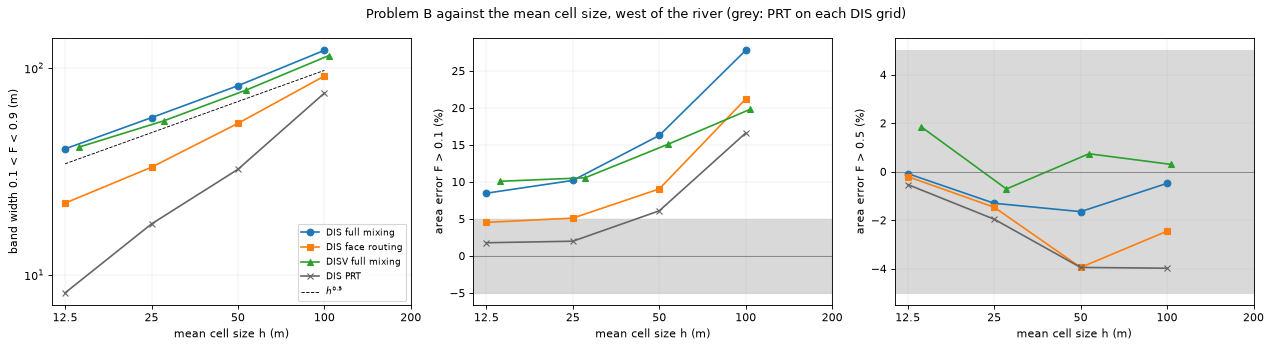

convergence rates: slope of log(metric) against log(mean cell size), four grids


band_width  area_err_0.1
kind method                                
DIS  PRT                 1.05          1.13
     face routing        0.68          0.75
     full mixing         0.53          0.58
DISV full mixing         0.51          0.36

In [9]:
series_b = [(f"{kind} {method}", {"kind": kind, "method": method}, style)
            for (kind, method), style in STYLES.items() if method != "cell-averaged exact"]
fig, axes = plt.subplots(1, 3, figsize=(16.0, 4.4))
helpers.plot_convergence(axes, table_b, series_b, guide_h=(12.5, 100.0))
axes[0].legend(fontsize=8)
fig.suptitle("Problem B against the mean cell size, west of the river (grey: PRT on each DIS grid)")
fig.tight_layout()
plt.show()

rates_b = helpers.rates_table(table_b, ["kind", "method"])
print("convergence rates: slope of log(metric) against log(mean cell size), four grids")
display(rates_b.round(2))

The picture is the one of problem A, with smaller numbers:

- The band of full mixing is 1.1 to 3.3 cells wide. It narrows at a rate of 0.53 on DIS and 0.51 on DISV. PRT on each coarser grid sets the floor of about 0.7 cells.
- The F > 0.5 area is within 4 % of the reference for every method at 50 m or less (2 % under full mixing).
- The F > 0.1 area of full mixing misses at most 0.13 % of the reference zone, on the coarsest Voronoi grid, and at most 0.02 % at 50 m or less. It is 8 to 16 % too large at 12.5 to 50 m, much less than in problem A. Here the zone edge is a recharge divide, close to where the water enters. In problem A it is a long streamline fed by lateral inflow, along which the spreading builds up.

How much of the extra spreading does face routing remove? The cell below compares the band widths in excess of the floor: the cell-averaged exact zone in problem A, and PRT on the same grid in problem B.

In [10]:
def removed(table: pd.DataFrame, keys: list[str], floor: str) -> pd.Series:
    # share of the band width in excess of the floor that face routing removes, per grid
    dis = table[table["kind"] == "DIS"].pivot_table(index=keys, columns="method", values="band_width")
    return 1.0 - (dis["face routing"] - dis[floor]) / (dis["full mixing"] - dis[floor])


excess = pd.concat({
    "problem A, 0 degrees": removed(table_a[table_a["angle"] == 0.0], ["h"], "cell-averaged exact"),
    "problem A, 30 degrees": removed(table_a[table_a["angle"] == 30.0], ["h"], "cell-averaged exact"),
    "problem B": removed(table_b, ["h"], "PRT"),
}, axis=1).sort_index(ascending=False)
print("share of the excess band width removed by face routing")
display(excess.round(2))

share of the excess band width removed by face routing


,"problem A, 0 degrees","problem A, 30 degrees",problem B
h,,,
200.0,0.14,0.38,NaN
100.0,0.63,0.33,0.66
50.0,0.34,0.51,0.57
25.0,0.38,0.54,0.61
12.5,0.38,0.51,0.57


Face routing removes 34 to 61 % of the excess band width at 50 m or less: 34 to 38 % with the flow along the rows, about half at 30° and 57 to 61 % in problem B. Its band at $h$ is close to that of full mixing at $h/2$ (0°) or $h/4$ (30°). It does not change the rate.

## 5. The orientation of the grid

Section 2 showed that the band depends on the angle between the flow and the cell faces. Tutorial 04 tested this on the tutorial aquifer: the 2 km × 2 km unconfined aquifer of tutorial 01, with recharge, a west constant head, a river and a well pumping 800 m³/d. The cell below repeats that test on four grids:

- the regular DIS grid of 50 m cells, whose rows run along the flow;
- squares turned by 45° to the flow, 47.1 m wide, one centred on the well (`hbd.build_rotated_squares`);
- the Voronoi grid of tutorial 04, about 50 m away from the well and the river;
- the same Voronoi grid with a background size of 25 m.

The width of the edge is measured along the north–south line $x$ = 500 m, north of the well. Along that line, $F$ is interpolated linearly between the cell centres. The width is the distance from where $F$ falls to 0.5 to where it falls to 0.1.

four grids built and traced in 3 s


,cells,expected area (km2),y at F = 0.5 (m),y at F = 0.1 (m),edge width (m)
"DIS, 50 m",1600.0,1.173,1322.0,1442.0,121.0
"squares turned 45 degrees, 47 m",1921.0,1.175,1330.0,1546.0,215.0
"DISV, 50 m",3241.0,1.178,1330.0,1517.0,186.0
"DISV, 25 m",8256.0,1.177,1330.0,1455.0,126.0


turned squares / DIS: 1.79; DISV 25 m / DISV 50 m: 0.68 (square root of 0.5: 0.71)


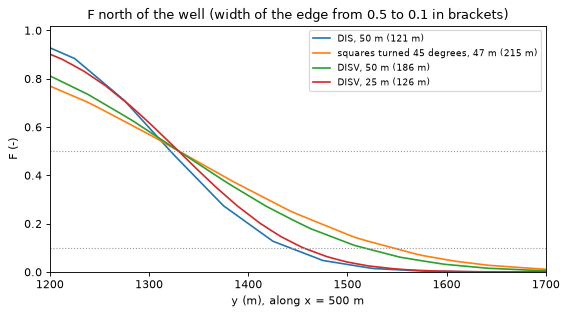

In [11]:
t0 = time.perf_counter()
example = {
    "DIS, 50 m": hbd.build_quickstart(WORK / "example_dis", MF6),
    "squares turned 45 degrees, 47 m": hbd.build_rotated_squares(WORK / "example_rotated", MF6, side=ROTATED_SIDE),
    "DISV, 50 m": hbd.build_voronoi(WORK / "example_disv50", MF6),
    "DISV, 25 m": hbd.build_voronoi(WORK / "example_disv25", MF6, **VORONOI_SIZES),
}
y = np.arange(0.0, example["DIS, 50 m"].spec.ly, 1.0)  # m, points along the line x = TRANSECT_X
profiles, edge_rows = {}, {}
for label, run in example.items():
    step = gs.read_step(run.ws, boundnames=True)
    F = gs.backward(step, {WELL: gs.select(step, boundnames=[WELL])}).fraction_through[WELL]
    profiles[label] = hbd.transect_profile(gs.export.cell_centres(run.grb_file), F, TRANSECT_X, y)
    y_half, y_tenth, width = hbd.band_width_north(y, profiles[label], 0.1, 0.5)
    edge_rows[label] = {"cells": step.n_cells, "expected area (km2)": float(F @ step.area) / 1e6,
                        "y at F = 0.5 (m)": y_half, "y at F = 0.1 (m)": y_tenth, "edge width (m)": width}
edges = pd.DataFrame(edge_rows).T
print(f"four grids built and traced in {time.perf_counter() - t0:.0f} s")
display(edges.round({"cells": 0, "expected area (km2)": 3, "y at F = 0.5 (m)": 0, "y at F = 0.1 (m)": 0,
                     "edge width (m)": 0}))
width = edges["edge width (m)"]
print(f"turned squares / DIS: {width.iloc[1] / width.iloc[0]:.2f}; "
      f"DISV 25 m / DISV 50 m: {width.iloc[3] / width.iloc[2]:.2f} (square root of 0.5: {np.sqrt(0.5):.2f})")

fig, ax = plt.subplots(figsize=(8.0, 4.0))
for label in example:
    ax.plot(y, profiles[label], label=f"{label} ({width[label]:.0f} m)")
for level in (0.1, 0.5):
    ax.axhline(level, color="0.6", ls=":", lw=1.0)
ax.set_xlim(1200.0, 1700.0)
ax.set_ylim(0.0, 1.02)
ax.set_xlabel(f"y (m), along x = {TRANSECT_X:g} m")
ax.set_ylabel("F (-)")
ax.set_title("F north of the well (width of the edge from 0.5 to 0.1 in brackets)")
ax.legend(fontsize=8)
plt.show()

On the regular grid, $F$ falls from 0.5 to 0.1 over 121 m. On the squares turned by 45°, the same band is 215 m wide, 1.8 times as wide, although these cells are a little smaller. Each turned square splits its water between two downstream faces, and every split moves some of the well's share sideways. The 50 m Voronoi grid lies between the two, at 186 m. Its faces lie at many angles to the flow. Halving its background cell size narrows the edge to 126 m, 0.68 times as wide, close to the square-root rule of sections 2 and 4. The expected areas $\sum_i F_i A_i$ of the four grids agree to within 0.5 %. The grid moves the edge, not the size of the zone.

## 6. The well's water by source and its mean travel time

Spreading moves water across the edge in both directions. Do the integral outputs, which sum over the whole zone, depend on it? The first table gives the river's share of the well water in problem B, under each method, on each grid. The second gives the mean travel time of all the water reaching the well, against the PRT reference, and the travel-time error of problem A against the analytical value.

In [12]:
shares = table_b.pivot_table(index=["kind", "h"], columns="method", values="share_RIV").sort_index(
    ascending=[True, False])[["full mixing", "face routing", "PRT"]]
print("problem B: share of the well water from the river (the rest is recharge)")
display(shares.round(4))
dis = shares.loc["DIS"]
spread = (dis.max(axis=1) - dis.min(axis=1)).max()
print(f"largest difference between the three methods on one DIS grid: {spread:.4f}")

time_b = table_b.pivot_table(index=["kind", "h"], columns="method", values="mean_time").sort_index(
    ascending=[True, False])[["full mixing", "face routing", "PRT"]]
time_b_err = time_b / prt["mean_time"] - 1.0
print(f"problem B: mean travel time relative to PRT on 12.5 m cells ({prt['mean_time']:.0f} d)")
display(pd.concat({"mean travel time (d)": time_b.round(0), "relative to the reference": time_b_err.round(3)}, axis=1))

time_a = table_a[table_a["method"] != "cell-averaged exact"].pivot_table(
    index=["kind", "h"], columns=["angle", "method"], values="travel_time_err").sort_index(ascending=[True, False])
print("problem A: mean travel time relative to the analytical value")
display(time_a.round(3))

problem B: share of the well water from the river (the rest is recharge)


method      full mixing  face routing     PRT
kind h                                       
DIS  100.0       0.0758        0.0758  0.0760
     50.0        0.1022        0.1022  0.1022
     25.0        0.1005        0.1005  0.1004
     12.5        0.0964        0.0964  0.0963
DISV 100.0       0.1864           NaN     NaN
     50.0        0.1128           NaN     NaN
     25.0        0.1121           NaN     NaN
     12.5        0.0911           NaN     NaN

largest difference between the three methods on one DIS grid: 0.0002
problem B: mean travel time relative to PRT on 12.5 m cells (9750 d)


mean travel time (d)                       \
method              full mixing face routing     PRT   
kind h                                                 
DIS  100.0               9940.0       9991.0  9786.0   
     50.0                9668.0       9686.0  9648.0   
     25.0                9686.0       9694.0  9691.0   
     12.5                9731.0       9735.0  9750.0   
DISV 100.0               8759.0          NaN     NaN   
     50.0                9555.0          NaN     NaN   
     25.0                9563.0          NaN     NaN   
     12.5                9787.0          NaN     NaN   

           relative to the reference                      
method                   full mixing face routing    PRT  
kind h                                                    
DIS  100.0                     0.019        0.025  0.004  
     50.0                     -0.008       -0.007 -0.011  
     25.0                     -0.007       -0.006 -0.006  
     12.5                     -0.002       -0.002  0.000  
DISV 100.0                    -0.102          NaN    NaN  
     50.0                     -0.020          NaN    NaN  
     25.0                     -0.019          NaN    NaN  
     12.5                      0.004          NaN    NaN

problem A: mean travel time relative to the analytical value


angle              0.0                      30.0            
method     face routing full mixing face routing full mixing
kind h                                                      
DIS  200.0        0.137       0.154        0.044      -0.017
     100.0        0.058       0.077        0.017      -0.028
     50.0         0.027       0.037        0.004      -0.025
     25.0         0.012       0.017       -0.000      -0.018
     12.5         0.005       0.007       -0.002      -0.012
DISV 200.0          NaN       0.092          NaN      -0.032
     100.0          NaN       0.017          NaN      -0.071
     50.0           NaN       0.036          NaN      -0.015
     25.0           NaN       0.008          NaN      -0.022
     12.5           NaN      -0.000          NaN      -0.017

- The **shares by source** are the same under full mixing, face routing and PRT on the same DIS grid, to within 0.0002, that is to three digits. They change with the grid only through the representation of the river. On the coarsest Voronoi grid the river cells are wide, and the river share is 0.186 instead of 0.076.
- The **mean travel time** is within 2.0 % of the PRT reference in problem B for cells of 50 m or less. On DIS grids it is within 0.9 %. The largest difference, −2.0 %, is on the 50 m Voronoi grid, whose mean cell size is 53 m. In problem A it is within 3.7 % of the analytical value for cells of 50 m or less.

The two kinds of time are not quite the same quantity. A PRT time stops when the particle enters the well cell. The Eulerian time of full mixing also includes the time the water spends in the well cell.

## 7. The numbers in one table

The cell collects each claim of this tutorial and computes it from the tables above. "Full mixing, 50 m or less" means the DIS and DISV grids of nominal size 12.5, 25 and 50 m. The Voronoi grids of nominal size 50 m have a mean cell size of 53 and 55 m.

In [13]:
mixing_a, mixing_b = table_a[table_a["method"] == "full mixing"], table_b[table_b["method"] == "full mixing"]
mixing = pd.concat([mixing_a, mixing_b])
fine_a, fine_b = mixing_a[mixing_a["h"] <= FINE], mixing_b[mixing_b["h"] <= FINE]
fine = pd.concat([fine_a, fine_b])
dis_mixing = mixing[mixing["kind"] == "DIS"]
band_rates = pd.concat([rates_a.xs("full mixing", level="method"), rates_b.xs("full mixing", level="method")])
all_rates = pd.concat([rates_a.drop("cell-averaged exact", level="method"), rates_b.drop("PRT", level="method")])
time_b_fine = time_b_err.loc[[k for k in time_b_err.index if k[1] <= FINE], "full mixing"]


def span(values, scale: float = 1.0, digits: int = 1) -> str:
    # 'min to max' of a series, scaled
    return f"{scale * min(values):.{digits}f} to {scale * max(values):.{digits}f}"


summary = pd.DataFrame([
    ("band 0.1 < F < 0.9 in cells, full mixing, all grids", "1.2 to 12",
     f"{span(mixing['band_cells'])} (DIS only: {span(dis_mixing['band_cells'])})"),
    ("rate of the band width (m) against h, full mixing", "about 0.5, fitted 0.4 to 0.6",
     f"{span(band_rates['band_width'], digits=2)} (with face routing: {span(all_rates['band_width'], digits=2)})"),
    ("|area error F > 0.5|, full mixing, 50 m or less", "within 5 %",
     f"at most {100 * fine['area_err_0.5'].abs().max():.1f} % (A {100 * fine_a['area_err_0.5'].abs().max():.1f} %, "
     f"B {100 * fine_b['area_err_0.5'].abs().max():.1f} %)"),
    ("share of the reference zone missed by F > 0.1, full mixing", "at most 0.1 %, every run",
     f"at most {100 * mixing['missed_0.1'].max():.2f} % (50 m or less: {100 * fine['missed_0.1'].max():.2f} %)"),
    ("area error F > 0.1, full mixing, 12.5 to 50 m, problem A", "+30 to +90 %", span(fine_a["area_err_0.1"], 100, 0) + " %"),
    ("area error F > 0.1, full mixing, 12.5 to 50 m, problem B", "+8 to +16 %", span(fine_b["area_err_0.1"], 100, 0) + " %"),
    ("edge width 0.5 to 0.1, tutorial aquifer: DIS / turned squares / DISV 25 m", "121 / 215 / 126 m",
     " / ".join(f"{width[k]:.0f}" for k in ("DIS, 50 m", "squares turned 45 degrees, 47 m", "DISV, 25 m")) + " m"),
    ("river share, largest difference between methods on one DIS grid", "same to three digits", f"{spread:.4f}"),
    ("|mean travel time error|, full mixing, 50 m or less, problem B (vs PRT)", "within 2 %",
     f"at most {100 * time_b_fine.abs().max():.1f} %"),
    ("|mean travel time error|, full mixing, 50 m or less, problem A (vs analytical)", "within 4 %",
     f"at most {100 * fine_a['travel_time_err'].abs().max():.1f} %"),
], columns=["quantity", "docs/dispersion_study.md", "this notebook"]).set_index("quantity")
display(summary)

,docs/dispersion_study.md,this notebook
quantity,,
"band 0.1 < F < 0.9 in cells, full mixing, all grids",1.2 to 12,1.1 to 11.8 (DIS only: 1.2 to 11.8)
"rate of the band width (m) against h, full mixing","about 0.5, fitted 0.4 to 0.6",0.41 to 0.54 (with face routing: 0.41 to 0.68)
"|area error F > 0.5|, full mixing, 50 m or less",within 5 %,"at most 4.5 % (A 4.5 %, B 1.8 %)"
"share of the reference zone missed by F > 0.1, full mixing","at most 0.1 %, every run",at most 0.13 % (50 m or less: 0.02 %)
"area error F > 0.1, full mixing, 12.5 to 50 m, problem A",+30 to +90 %,30 to 90 %
"area error F > 0.1, full mixing, 12.5 to 50 m, problem B",+8 to +16 %,8 to 16 %
"edge width 0.5 to 0.1, tutorial aquifer: DIS / turned squares / DISV 25 m",121 / 215 / 126 m,121 / 215 / 126 m
"river share, largest difference between methods on one DIS grid",same to three digits,0.0002
"|mean travel time error|, full mixing, 50 m or less, problem B (vs PRT)",within 2 %,at most 2.0 %


Every number agrees with the study, with two small differences in how a claim is worded:

- The band is **1.1** cells wide, not 1.2, on the coarsest Voronoi grid of problem B (mean cell size 104 m). On DIS grids the range is 1.2 to 12 cells.
- The F > 0.1 area of full mixing missed **0.13 %** of the reference zone on that same grid. That is the only run above 0.1 %. With cells of 50 m or less it missed at most 0.02 %.

The rates of the band width under full mixing are 0.41 to 0.54. With face routing they reach 0.68 (problem B). The area errors at F > 0.1 converge at rates of 0.36 to 0.75.

## Checks

The cell below asserts the main results, so that a change in the code or the models that moves them is noticed.

In [14]:
assert fine["area_err_0.5"].abs().max() < 0.05  # F > 0.5 area within 5 % at 50 m or less
assert fine["missed_0.1"].max() < 1e-3 and mixing["missed_0.1"].max() < 2e-3
assert (fine_a["area_err_0.1"] > 0.25).all() and (fine_b["area_err_0.1"].between(0.05, 0.2)).all()
assert band_rates["band_width"].between(0.4, 0.6).all()  # band narrows as about h^0.5
assert spread < 5e-4  # shares by source to three digits
assert time_b_fine.abs().max() < 0.021 and fine_a["travel_time_err"].abs().max() < 0.04
assert width["squares turned 45 degrees, 47 m"] > 1.5 * width["DIS, 50 m"] and width["DISV, 25 m"] < width["DISV, 50 m"]
assert abs(prt["captured_flow"] / reference["well_inflow"] - 1.0) < 2e-3  # PRT captures the pumping
print("all checks passed")
print(f"notebook run time: {time.perf_counter() - START:.0f} s")

all checks passed
notebook run time: 41 s


## Key points

- Full mixing smears the edge of a capture zone over a band of cells. On the two test problems the band between F = 0.1 and F = 0.9 is about 1 to 12 cells wide. In metres it narrows only as about the square root of the cell size, so the finer the grid, the more cells it spans.
- The **F > 0.5 area** is an unbiased estimate of the advective capture zone. With cells of 50 m or less it was within 5 % of the analytical or particle zone.
- The **F > 0.1 area** is a conservative envelope: it missed almost none of the reference zone. It costs area: 30 to 90 % too large for flow converging on a well from a regional gradient, 8 to 16 % for a recharge-fed zone.
- The **orientation of the cell faces** matters as much as their size. Squares turned by 45° to the flow made the edge 1.8 times as wide. Voronoi grids spread the edge no less than squares.
- **Face routing** removes about a third to 60 % of the extra spreading, the effect of halving or quartering the cells. It does not change the half-order rate.
- **Integral outputs** barely depend on the mixing: the shares by source agree to three digits with particles on the same grid, and the mean travel time to within 2 to 4 %.
- To delineate an advective capture zone, use the F = 0.5 contour on cells of 50 m or less, or particles. Use a low threshold only as an outer bound.

## Next

Back to the [tutorial list](../README.md). The full study, with transient tracking and the time-step effect, is [`docs/dispersion_study.md`](../../docs/dispersion_study.md). Tutorial [08](../08_transient_tracking/08_transient_tracking.ipynb) shows the numerical dispersion in time and the transport sub-steps that reduce it.